
# Data Preparation of the Heart Diagnoses file

In [172]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
from src.utils import data_understanding as du





heart_diagnoses_df = pd.read_csv("../../data/raw/heart_diagnoses_1.csv")
heart_diagnoses_df['subject_id'].nunique()

4392

## Data Cleaning

In [173]:
heart_diagnoses_df



,note_id,subject_id,hadm_id,note_type,note_seq,charttime,storetime,HPI,physical_exam,chief_complaint,...,ECG,MRI,reports,subject_id_dx,icd_code,long_title,gender,age,anchor_year,dod
0,10000980-DS-20,10000980,29654838,DS,20,2188-01-06 03:00:00,2188-01-07 23:49:00,":\n___ yo woman with h/o hypertension, hyperli...","Admission exam:\nGENERAL- Oriented x3. Mood, a...",\nShortness of breath\n \n,...,['___ 7:56:06 ___ \nBaseline artifact. Sinus...,[],Sinus bradycardia with sinus arrhythmia | Prol...,10000980,I50,Heart failure,F,75.0,2186.0,2193-08-26
1,10000980-DS-21,10000980,26913865,DS,21,2189-07-04 03:00:00,2189-07-04 22:50:00,":\nThis is a ___ M with history of diabetes, d...",ADMISSION EXAM:\nGeneral- appears comfortable...,\ndyspnea\n \n,...,[],[],Sinus bradycardia with sinus arrhythmia | Prol...,10000980,I21,Acute myocardial infarction,F,75.0,2186.0,2193-08-26
2,10002013-DS-8,10002013,24760295,DS,8,2160-07-13 03:00:00,2160-07-15 16:59:00,":\n___ w/ PMH of CAD s/p PCI x3, s/p off-pump ...",Admission:\nVS- T 99.4 BP 157/88 HR 118 RR 24 ...,\nchest pain\n \n,...,['on admission- Sinus tachycardia. Extensive S...,[],Sinus tachycardia | Extensive ST-T changes may...,10002013,I21,Acute myocardial infarction,NaN,NaN,NaN,NaN
3,10002155-DS-8,10002155,23822395,DS,8,2129-08-19 03:00:00,2129-08-20 15:29:00,:\n___ is a ___ yo female with a past medical ...,"GENERAL: WDWN in NAD. Oriented x3. Mood, affec...",\nchest pressure\n \n,...,[': new LBBB with STE in V1 -V3 & V5 that in ...,[],*** CONSIDER ACUTE ST ELEVATION MI *** | Sinus...,10002155,I21,Acute myocardial infarction,NaN,NaN,NaN,NaN
4,10004457-DS-10,10004457,28723315,DS,10,2141-08-14 03:00:00,2141-08-14 21:50:00,:\nMr. ___ is a ___ with a hx of CAD (s/p DES ...,On Admission:\nVS- 97.8 157/64 101 18 98% RA \...,"\nAbnormal Stress Test, New AI\n \n",...,['(see exercise report for details). Resting s...,[],Sinus rhythm | Normal ECG,10004457,I35,Nonrheumatic aortic valve disorders,M,66.0,2140.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4859,13690559-DS-19,19998596,24860241,DS,19,2180-01-24 03:00:00,2180-01-24 20:12:00,:\nMs ___ is a ___ year old woman with carotid...,ADMISSION EXAM\n=====================\nVITALS:...,\nRight shoulder pain\n \n,...,['___:\nAtrial flutter with 4:1 conduction and...,[],Possible atrial flutter with rapid ventricular...,13690559,I48,Atrial fibrillation and flutter,NaN,NaN,NaN,NaN
4860,14997789-DS-12,19998597,23720781,DS,12,2131-10-11 03:00:00,2131-10-11 16:17:00,:\nMs. ___ is a ___ woman with renal cell carc...,Physical Exam:\nVS: T: T 95.7 bp 102/60 HR 1...,\nDyspnea\n \n,...,[],[],Sinus tachycardia. | Possible anterior infarct...,14997789,I31,Other diseases of pericardium,NaN,NaN,NaN,NaN
4861,10754991-DS-13,19998598,26940500,DS,13,2135-04-03 03:00:00,2135-04-05 00:12:00,":\n___ T2DM, fibromyalgia, GERD, hypothyroidis...",=================\nADMISSION EXAM:\n==========...,\nPalpitations\n \n,...,['(___): Narrow complex tachycardia. Supravent...,[],Supraventricular tachycardia | Sinus rhythm | ...,10754991,I47,Paroxysmal tachycardia,NaN,NaN,NaN,NaN
4862,17922874-DS-8,19998599,20343031,DS,8,2158-05-23 03:00:00,2158-05-23 20:55:00,":\n___ with H/O of type 2 diabetes mellitus, h...","General: Middle aged Caucasian man in NAD, com...","\nAbdominal pain, nausea, vomiting, and diarrh...",...,['Study Date of ___ 7:51:52 ___\nSinus rhythm ...,[],*** CONSIDER ACUTE ST ELEVATION MI *** | Sinus...,17922874,I30,Acute pericarditis,NaN,NaN,NaN,NaN


In [174]:
import re

def detect_gender_regex(text):
    if pd.isna(text):
        return 'unknown'
    
    text_lower = text.lower()

    if re.search(r'\bm\b', text_lower):
        return 'M'
    if re.search(r'\bf\b', text_lower):
        return 'F'
    
    # Title patterns (with word boundaries)
    if re.search(r'\b(mr\.?|mister)\b', text_lower):
        return 'M'
    if re.search(r'\b(mrs?\.?|miss|ms\.?)\b', text_lower):
        return 'F'
    
    # Pronoun patterns
    if re.search(r'\b(he|his|him|himself)\b', text_lower):
        return 'M'
    if re.search(r'\b(she|her|hers|herself)\b', text_lower):
        return 'F'
    
    # Gendered nouns
    if re.search(r'\b(man|men|male|boy|gentleman)\b', text_lower):
        return 'M'
    if re.search(r'\b(woman|women|female|girl|lady)\b', text_lower):
        return 'F'
    
    return np.nan

heart_diagnoses_df['gender'] = heart_diagnoses_df['HPI'].apply(detect_gender_regex)
mask = heart_diagnoses_df['gender'].isna()

heart_diagnoses_df[mask]


,note_id,subject_id,hadm_id,note_type,note_seq,charttime,storetime,HPI,physical_exam,chief_complaint,...,ECG,MRI,reports,subject_id_dx,icd_code,long_title,gender,age,anchor_year,dod
196,10449928-DS-11,10449928,21406053,DS,11,2178-08-08 03:00:00,2178-08-10 18:23:00,":\n___ with morbid obesity, OSA s/p palate sur...",ADMISSION PHYSICAL EXAM\nV/S:T 98.3 HR 78 BP 1...,\ndyspnea on exertion\n \n,...,['Study Date of ___ 3:02:04 ___ \n\nSinus rhy...,[],Sinus rhythm | Rightward axis | Borderline ECG,10449928,I50,Heart failure,NaN,NaN,NaN,NaN
844,11829756-DS-17,11829756,21996515,DS,17,2152-05-01 03:00:00,2152-05-07 20:02:00,":\n___ with PMH DM, chronic headache, sent fro...","*Admission Physical*\nVitals- 98.0, 106/57, 97...","\nnew afib, ___, elevated glucose, PND\n \n",...,['___: Sinus rhythm. Normal tracing. No major ...,[],Sinus rhythm. | Normal ECG | Atrial fibrillati...,11829756,I50,Heart failure,NaN,62.0,2152.0,NaN
1008,12118363-DS-18,12118363,23198189,DS,18,2139-08-24 03:00:00,2139-08-27 18:17:00,":\n___ CABG ___ (LIMA to LAD, SVG-D-OM, SVG-PD...",`ADMISSION PHYSICAL EXAMINATION: \n==========...,\nSTEMI \n \n,...,['___.\nThe limb lead voltage appears diminish...,[],"Sinus tachycardia | RBBB and LPFB | ST depr, c...",12118363,I21,Acute myocardial infarction,NaN,NaN,NaN,NaN
1241,12585868-DS-11,12585868,27665318,DS,11,2172-01-01 03:00:00,2172-01-02 01:14:00,":\n___, no significant PMH, presenting from __...","ADMISSION PHYSICAL EXAMINATION: \nVS: 97.6, 9...",\nChest pain and DOE\n \n,...,[],[],"Age not entered, assumed to be 50 years old f...",12585868,I30,Acute pericarditis,NaN,55.0,2171.0,NaN
1431,12977557-DS-4,12977557,20558377,DS,4,2189-06-16 03:00:00,2189-06-16 21:00:00,":\n___ with history of CAD (3VD, s/p CABG, ___...",ADMISSION EXAM:\nVS: 98.5; 109-146/67-94; 79-1...,\nchest pain\n \n,...,[],[],Sinus rhythm with borderline 1st degree A-V bl...,12977557,I48,Atrial fibrillation and flutter,NaN,NaN,NaN,NaN
1749,13639456-DS-22,13639456,20780736,DS,22,2113-01-03 03:00:00,2113-01-03 20:15:00,":\n___ PMH CAD, HTN, hyperlipidemia, atrial fi...","VS: T 96.7, BP 90-109/60-72, HR V paced at 70,...",\nchest pain\n \n,...,[],[],Accelerated idioventricular rhythm | *** if rh...,13639456,I35,Nonrheumatic aortic valve disorders,NaN,NaN,NaN,NaN
2030,14220470-DS-21,14220470,27285325,DS,21,2141-11-01 03:00:00,2141-11-02 23:44:00,:\n___ with unknown PMH p/w LM STEMI. Pt initi...,Admission Exam: \nVS: T=98.8R BP=119/50 HR=98 ...,\nchest pain\n \n,...,['Study Date of ___ 1:36:24 ___ \n\nSinus tac...,[],Sinus tachycardia with PVC(s). | Indeterminate...,14220470,I21,Acute myocardial infarction,NaN,NaN,NaN,NaN
2163,14514717-DS-13,14514717,21037073,DS,13,2178-12-13 03:00:00,2178-12-14 12:46:00,":\n___ with no past medical history, transfer ...",Admission Exam:\nVS: 97.5 142/81 81 18 96% on ...,\nChest Pain\n \n,...,['___:\nSinus rhythm. Left atrial abnormality....,[],Sinus rhythm | Possible left ventricular hyper...,14514717,I21,Acute myocardial infarction,NaN,NaN,NaN,NaN
2186,14566798-DS-24,14566798,21273039,DS,24,2140-01-29 03:00:00,2140-01-29 16:25:00,":\n___ with alcoholism, afib not on warfarin, ...",PHYSICAL EXAM upon transfer from MICU to floor...,\ndyspnea on exertion\n \n,...,['Study Date of ___ 5:58:50 AM \n\nAtrial fib...,[],Atrial fibrillation | Leftward axis | Poor R w...,14566798,I50,Heart failure,NaN,NaN,NaN,NaN
2611,15466684-DS-15,15466684,23594624,DS,15,2176-01-24 03:00:00,2176-01-26 02:06:00,":\n___ with hx of dCHF, HTN, CVA, prior syncop...",Exam on Admission:VS: 98.4 101/46 68 18 99% on...,\nSyncope\n \n,...,['(___): Sinus rhythm with change in the atria...,[],Sinus rhythm. | Possible septal infarct - age ...,15466684,I42,Cardiomyopathy,NaN,NaN,NaN,NaN


In [175]:
#drop columns with information not relevant for the analysis: free text columns, reports columns,unusefull columns
heart_diagnoses_df = heart_diagnoses_df.drop(columns=["CT", "MRI", "X-ray", "Ultrasound", "ECG", "CATH", "invasions", "reports","chief_complaint", "physical_exam","HPI","anchor_year","note_seq","note_type","charttime","storetime"])
heart_diagnoses_df_columns= du.get_cols(heart_diagnoses_df)
print("Columns in heart diagnoses dataset:",heart_diagnoses_df_columns) 


Columns in heart diagnoses dataset: ['note_id', 'subject_id', 'hadm_id', 'subject_id_dx', 'icd_code', 'long_title', 'gender', 'age', 'dod']


In [176]:
#Missing value analysis
#age and gender have missing values but they can be usfull for the analysis so we will keep them
#dod has many missing values can be  that the patient witout dod is alive or the data is missing, so is ambiguous, we will drop it
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["dod"])
heart_diagnoses_df['subject_id'].nunique()


4392

In [177]:
# Calcola il numero di occorrenze per ogni icd_code
icd_counts = heart_diagnoses_df['icd_code'].value_counts()

# Calcola Q1, Q3 e IQR
q1 = icd_counts.quantile(0.25)
q3 = icd_counts.quantile(0.75)
iqr = q3 - q1

# Calcola i limiti
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f"Q1 (25%): {q1}")
print(f"Q3 (75%): {q3}")
print(f"IQR: {iqr}")
print(f"Lower limit: {lower_limit}")
print(f"Upper limit: {upper_limit}")

# Identifica gli icd_code da rimuovere (sotto il limite inferiore)
rare_icd_codes_iqr = icd_counts[icd_counts < lower_limit].index

print(f"\nICD codes da rimuovere (sotto il limite): {len(rare_icd_codes_iqr)}")
print(rare_icd_codes_iqr.tolist())

# Rimuovi gli icd_code rari
heart_diagnoses_df = heart_diagnoses_df[~heart_diagnoses_df['icd_code'].isin(rare_icd_codes_iqr)]

print(f"\nShape dopo rimozione: {heart_diagnoses_df.shape}")
print(f"ICD codes rimasti: {heart_diagnoses_df['icd_code'].nunique()}")
icd_counts_after = heart_diagnoses_df['icd_code'].value_counts()
icd_counts_after

Q1 (25%): 15.0
Q3 (75%): 172.5
IQR: 157.5
Lower limit: -221.25
Upper limit: 408.75

ICD codes da rimuovere (sotto il limite): 0
[]

Shape dopo rimozione: (4864, 8)
ICD codes rimasti: 20


icd_code
I50    1447
I21    1434
I25     645
I48     438
I35     231
I31     153
I47     130
I30      83
I44      70
I34      50
I33      38
I20      36
I49      35
I42      33
I40      16
I24      12
I22       5
I45       5
I46       2
I36       1
Name: count, dtype: int64

In [178]:
# Step 1: Raggruppa per paziente e controlla se ha almeno un age noto
patients_with_age_info = (
    heart_diagnoses_df.groupby("subject_id")["age"]
    .apply(lambda x: x.notna().any())   # True se almeno un record ha gender
)

# Step 2: Filtra i pazienti senza nessuna info sul sesso
patients_without_age_info = patients_with_age_info[~patients_with_age_info]

# Step 3: Conta quanti sono
num_patients_without_age_info = patients_without_age_info.shape[0]

print(f"✓ Numero di pazienti senza nessuna info sul sesso: {num_patients_without_age_info}")

✓ Numero di pazienti senza nessuna info sul sesso: 3128


In [179]:
# Caso 1: Pazienti con una sola ammissione → imputazione con mediana ICD

admissions_per_patient = (
    heart_diagnoses_df.groupby('subject_id')['hadm_id']
    .nunique()
    .reset_index()
)
admissions_per_patient.columns = ['subject_id', 'num_admissions']
single_admission_patients = admissions_per_patient[
    admissions_per_patient['num_admissions'] == 1
]['subject_id'].tolist()
median_age_per_icd = (
    heart_diagnoses_df[heart_diagnoses_df['age'].notna()]
    .groupby('icd_code')['age']
    .median()
    .astype(int)
    .reset_index()
)
median_age_per_icd.columns = ['icd_code', 'median_age']

mask_single_admission = heart_diagnoses_df['subject_id'].isin(single_admission_patients)
mask_missing_age = heart_diagnoses_df['age'].isna()
mask_has_median = heart_diagnoses_df['icd_code'].isin(median_age_per_icd['icd_code'])

rows_to_fill_single = heart_diagnoses_df[mask_single_admission & mask_missing_age & mask_has_median]

for idx in rows_to_fill_single.index:
    icd_code = heart_diagnoses_df.loc[idx, 'icd_code']
    median_age = median_age_per_icd[median_age_per_icd['icd_code'] == icd_code]['median_age'].values
    if len(median_age) > 0:
        heart_diagnoses_df.loc[idx, 'age'] = median_age[0]

print(f"✓ Età imputata con mediana ICD per {rows_to_fill_single.shape[0]} record (single admission)")


✓ Età imputata con mediana ICD per 2823 record (single admission)


In [180]:
# Caso 2: Pazienti con più ammissioni e almeno un'età osservata → usa direttamente quell'età
multi_admission_patients = admissions_per_patient[admissions_per_patient['num_admissions'] > 1]['subject_id'].tolist()

observed_age_per_patient = (
    heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(multi_admission_patients) & heart_diagnoses_df['age'].notna()]
    .groupby('subject_id')['age']
    .first()   # usa direttamente la prima età trovata
    .reset_index()
    .rename(columns={'age': 'patient_observed_age'})
)

# Merge nel dataset
heart_diagnoses_df = heart_diagnoses_df.merge(observed_age_per_patient, on='subject_id', how='left')

mask_multi_admission = heart_diagnoses_df['subject_id'].isin(multi_admission_patients)
mask_missing_age = heart_diagnoses_df['age'].isna()
mask_has_observed = heart_diagnoses_df['patient_observed_age'].notna()

rows_to_fill_observed = heart_diagnoses_df[mask_multi_admission & mask_missing_age & mask_has_observed]

for idx in rows_to_fill_observed.index:
    heart_diagnoses_df.loc[idx, 'age'] = heart_diagnoses_df.loc[idx, 'patient_observed_age']

print(f"✓ Età imputata con valore osservato per {rows_to_fill_observed.shape[0]} record (multi admission con info)")
heart_diagnoses_df = heart_diagnoses_df.drop(columns=['patient_observed_age'])


✓ Età imputata con valore osservato per 0 record (multi admission con info)


In [181]:
# Caso 3: Pazienti con più ammissioni e nessuna età osservata → imputazione con mediana delle mediane ICD
df_with_median = heart_diagnoses_df.merge(median_age_per_icd, on='icd_code', how='left')

median_of_medians_per_patient = (
    df_with_median[df_with_median['subject_id'].isin(multi_admission_patients)]
    .groupby('subject_id')['median_age']
    .median()
    .reset_index()
    .rename(columns={'median_age': 'patient_imputed_age'})
)

# Merge nel dataset
heart_diagnoses_df = heart_diagnoses_df.merge(median_of_medians_per_patient, on='subject_id', how='left')

mask_multi_admission = heart_diagnoses_df['subject_id'].isin(multi_admission_patients)
mask_missing_age = heart_diagnoses_df['age'].isna()
mask_has_imputed = heart_diagnoses_df['patient_imputed_age'].notna()

rows_to_fill_imputed = heart_diagnoses_df[mask_multi_admission & mask_missing_age & mask_has_imputed]

for idx in rows_to_fill_imputed.index:
    heart_diagnoses_df.loc[idx, 'age'] = heart_diagnoses_df.loc[idx, 'patient_imputed_age']

print(f"✓ Età imputata con mediana delle mediane ICD per {rows_to_fill_imputed.shape[0]} record (multi admission senza info)")
heart_diagnoses_df = heart_diagnoses_df.drop(columns=['patient_imputed_age'])



✓ Età imputata con mediana delle mediane ICD per 672 record (multi admission senza info)


In [182]:
#print the number of patient without age information

# 1. Trova i soggetti che hanno TUTTI i record con age mancante
subjects_missing_age = (
    heart_diagnoses_df.groupby("subject_id")["age"]
    .apply(lambda x: x.isna().all())
)

# 2. Lista dei soggetti senza età
subjects_missing_age_list = subjects_missing_age[subjects_missing_age].index.tolist()

# 3. Filtra il dataset per questi soggetti
df_missing_age = heart_diagnoses_df[heart_diagnoses_df["subject_id"].isin(subjects_missing_age_list)]

# 4. Raggruppa e stampa gli ICD code per ciascun soggetto
icd_per_missing_subject = (
    df_missing_age.groupby("subject_id")["icd_code"]
    .apply(lambda x: sorted(x.dropna().unique().tolist()))
    .reset_index(name="icd_codes")
)

print(icd_per_missing_subject)






   subject_id icd_codes
0    11738511     [I46]
1    14493463     [I45]
2    16119864     [I46]
3    17310727     [I45]
4    17585582     [I45]
5    19918694     [I45]


In [183]:
#per questi in base al web mettere come età 70 anni
# Step 5: Sostituisci l'età mancante con 70 per i soggetti senza alcuna info
mode_age=heart_diagnoses_df['age'].mode()[0]
mask_missing_subjects = heart_diagnoses_df["subject_id"].isin(subjects_missing_age_list) & heart_diagnoses_df["age"].isna()

heart_diagnoses_df.loc[mask_missing_subjects, "age"] = mode_age

# Log finale
print(f"✓ Età imputata con la moda dell'età per {mask_missing_subjects.sum()} record")
print(heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(subjects_missing_age_list)][['subject_id','icd_code','age']].head(20))




✓ Età imputata con la moda dell'età per 6 record
      subject_id icd_code   age
791     11738511      I46  75.0
2153    14493463      I45  75.0
2942    16119864      I46  75.0
3467    17310727      I45  75.0
3625    17585582      I45  75.0
4712    19918694      I45  75.0


<Axes: xlabel='age', ylabel='Count'>

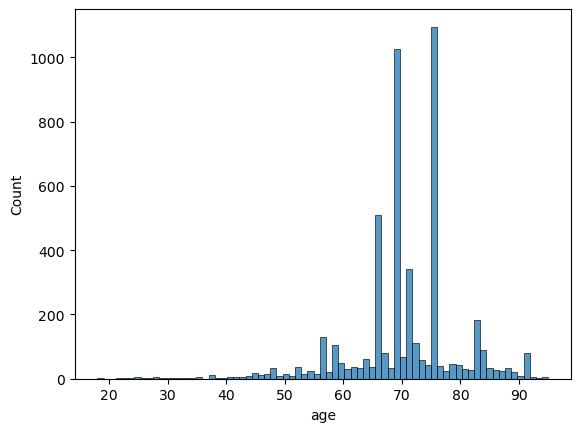

In [184]:
#distributiom of the age
sns.histplot(heart_diagnoses_df, x="age")

In [185]:
# Step 1: Raggruppa per paziente e controlla se ha almeno un gender noto
patients_with_gender_info = (
    heart_diagnoses_df.groupby("subject_id")["gender"]
    .apply(lambda x: x.notna().any())   # True se almeno un record ha gender
)

# Step 2: Filtra i pazienti senza nessuna info sul sesso
patients_without_gender_info = patients_with_gender_info[~patients_with_gender_info]

# Step 3: Conta quanti sono
num_patients_without_gender_info = patients_without_gender_info.shape[0]

print(f"✓ Numero di pazienti senza nessuna info sul sesso: {num_patients_without_gender_info}")



✓ Numero di pazienti senza nessuna info sul sesso: 17


In [186]:
#metto il gender per chi ha solo un hd mantenendo la proporzione
np.random.seed(42)

def fill_with_proportions(group, global_props=None):
    missing_mask = group['gender'].isna()
    if missing_mask.sum() == 0:
        return group
    
    # Conta valori disponibili
    value_counts = group['gender'].value_counts()
    
    if value_counts.empty:
        # Se non ci sono valori osservati per quell'ICD
        if global_props is not None:
            # Usa proporzioni globali
            choices = np.random.choice(global_props.index, size=missing_mask.sum(), p=global_props.values)
            group.loc[missing_mask, 'gender'] = choices
        else:
            # Altrimenti assegna un default (es. 'M')
            group.loc[missing_mask, 'gender'] = 'M'
    else:
        # Usa proporzioni locali ICD
        proportions = value_counts / value_counts.sum()
        choices = np.random.choice(value_counts.index, size=missing_mask.sum(), p=proportions.values)
        group.loc[missing_mask, 'gender'] = choices
    
    return group

# Calcola proporzioni globali F/M
global_props = heart_diagnoses_df['gender'].value_counts(normalize=True)

# Applica solo ai pazienti con una sola ammissione
df_single_admission = heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(single_admission_patients)]
df_single_admission = df_single_admission.groupby('icd_code', group_keys=False).apply(fill_with_proportions, global_props=global_props)

# Aggiorna dataset originale
heart_diagnoses_df.update(df_single_admission)

print(f"✓ Missing values in gender (single admission): {df_single_admission['gender'].isna().sum()}")
print(df_single_admission['gender'].value_counts())

✓ Missing values in gender (single admission): 0
gender
M    2435
F    1566
Name: count, dtype: int64


/var/folders/d3/b_pspz_d64lf1hwbztqr9l1r0000gn/T/ipykernel_82505/1116455350.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_single_admission = df_single_admission.groupby('icd_code', group_keys=False).apply(fill_with_proportions, global_props=global_props)


In [187]:
# Fill missing gender using other admissions of the same subject
multi_admission_subjects = (
    heart_diagnoses_df.groupby('subject_id')['hadm_id'].nunique().gt(1)
)

gender_lookup = (
    heart_diagnoses_df[heart_diagnoses_df['gender'].notna()]
    .sort_values('hadm_id')
    .drop_duplicates('subject_id', keep='first')
    .set_index('subject_id')['gender']
)

mask_missing_gender = heart_diagnoses_df['gender'].isna()
mask_multi_with_gender = (
    multi_admission_subjects.reindex(heart_diagnoses_df['subject_id']).fillna(False).values &
    heart_diagnoses_df['subject_id'].isin(gender_lookup.index)
)

heart_diagnoses_df.loc[mask_missing_gender & mask_multi_with_gender, 'gender'] = (
    heart_diagnoses_df.loc[mask_missing_gender & mask_multi_with_gender, 'subject_id']
    .map(gender_lookup)
)

print(f"✓ Missing values in gender (multi admission): {heart_diagnoses_df['gender'].isna().sum()}")

✓ Missing values in gender (multi admission): 0


In [188]:
#Step 1: Raggruppa per paziente e controlla se ha almeno un gender noto
patients_with_gender_info = (
    heart_diagnoses_df.groupby("subject_id")["gender"]
    .apply(lambda x: x.notna().any())   # True se almeno un record ha gender
)

# Step 2: Filtra i pazienti senza nessuna info sul sesso
patients_without_gender_info = patients_with_gender_info[~patients_with_gender_info]

# Step 3: Conta quanti sono
num_patients_without_gender_info = patients_without_gender_info.shape[0]

print(f"✓ Numero di pazienti senza nessuna info sul sesso: {num_patients_without_gender_info}")


✓ Numero di pazienti senza nessuna info sul sesso: 0


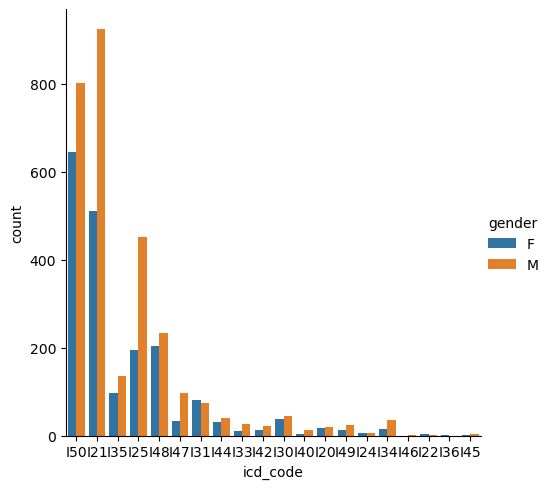

In [189]:
#to visualize the number of female and men for each icd_code
sns.catplot(data=heart_diagnoses_df, x="icd_code", hue="gender",kind="count")

In [190]:
#drop columns that have info achieved in another coloumns 
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["note_id","subject_id_dx"])


In [191]:
#final dataset analysis
print("Shape of heart diagnoses dataset:",)
heart_diagnoses_df.shape
print("Info of heart diagnoses dataset:")
heart_diagnoses_df.info()
heart_diagnoses_df_none=du.get_cols_with_none(heart_diagnoses_df)
print("Missing values in each column of heart diagnoses dataset:\n",heart_diagnoses_df_none)
print("Basic statistics of heart diagnoses dataset:")
du.get_basic_stats(heart_diagnoses_df)


Shape of heart diagnoses dataset:
Info of heart diagnoses dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4864 entries, 0 to 4863
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   subject_id  4864 non-null   int64  
 1   hadm_id     4864 non-null   int64  
 2   icd_code    4864 non-null   object 
 3   long_title  4864 non-null   object 
 4   gender      4864 non-null   object 
 5   age         4864 non-null   float64
dtypes: float64(1), int64(2), object(3)
memory usage: 228.1+ KB
Missing values in each column of heart diagnoses dataset:
 subject_id    False
hadm_id       False
icd_code      False
long_title    False
gender        False
age           False
dtype: bool
Basic statistics of heart diagnoses dataset:


,age
count,4864.000000
mean,70.283923
std,9.316514
min,18.000000
25%,66.000000
50%,70.000000
75%,75.000000
max,95.000000


In [192]:
# mean and median age for each icd_code
icd_stats = heart_diagnoses_df.groupby('icd_code')['age'].agg(['mean', 'median']).reset_index()
icd_stats.columns = ['icd_code', 'mean_age', 'median_age']
print("Mean and median age for each ICD code:\n", icd_stats)

Mean and median age for each ICD code:
    icd_code   mean_age  median_age
0       I20  57.027778        60.0
1       I21  68.951534        69.0
2       I22  87.000000        90.0
3       I24  69.333333        69.0
4       I25  66.216279        66.0
5       I30  59.602410        59.0
6       I31  57.794118        57.0
7       I33  57.236842        59.0
8       I34  71.200000        71.0
9       I35  81.746753        83.0
10      I36  60.000000        60.0
11      I40  49.562500        52.0
12      I42  51.227273        48.0
13      I44  82.357143        84.0
14      I45  75.000000        75.0
15      I46  75.000000        75.0
16      I47  68.965385        69.0
17      I48  71.116438        71.0
18      I49  63.942857        64.0
19      I50  74.195577        75.0


<Axes: xlabel='icd_code', ylabel='Count'>

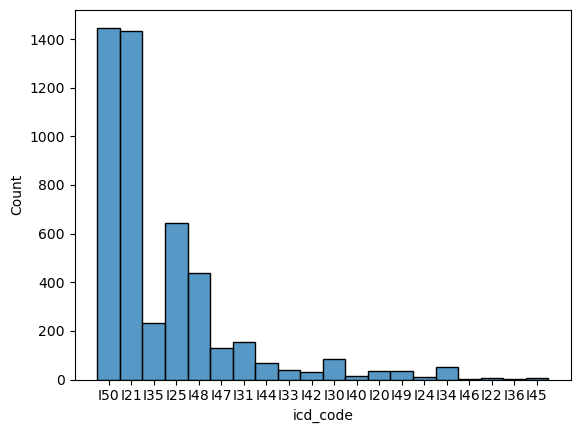

In [193]:
# visualize the new icd_code distribution
sns.histplot(heart_diagnoses_df, x="icd_code")


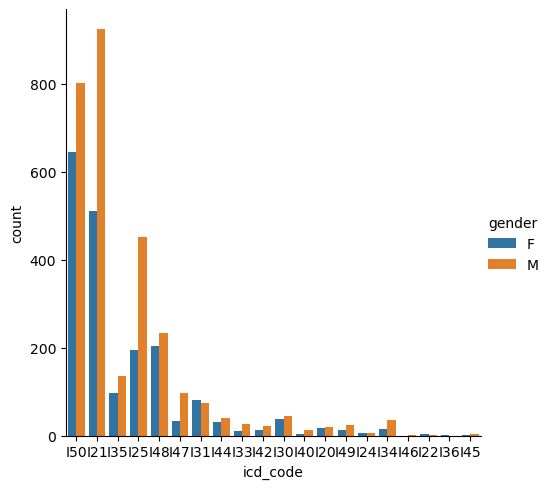

In [194]:
# visualize the number of female and men for each icd_code
sns.catplot(data=heart_diagnoses_df, x="icd_code", hue="gender",kind="count")

<Axes: xlabel='icd_code', ylabel='age'>

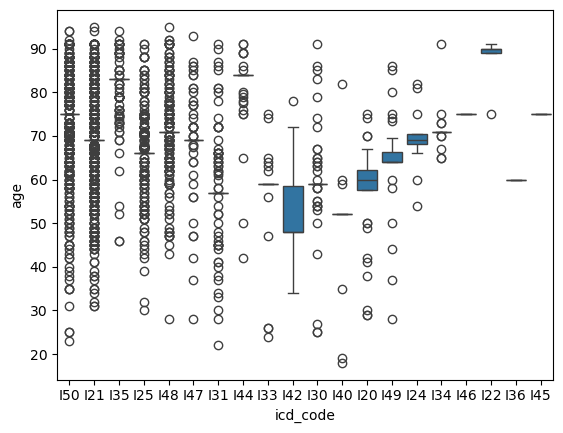

In [195]:
# visualize for each icd_code the age of the patient 
sns.boxplot(data=heart_diagnoses_df,x="icd_code",y="age")

In [196]:

heart_diagnoses_df.to_csv("../../data/processed/hd.csv", index=False)

In [197]:
heart_diagnoses_df

,subject_id,hadm_id,icd_code,long_title,gender,age
0,10000980,29654838,I50,Heart failure,F,75.0
1,10000980,26913865,I21,Acute myocardial infarction,M,75.0
2,10002013,24760295,I21,Acute myocardial infarction,F,69.0
3,10002155,23822395,I21,Acute myocardial infarction,F,69.0
4,10004457,28723315,I35,Nonrheumatic aortic valve disorders,M,66.0
...,...,...,...,...,...,...
4859,19998596,24860241,I48,Atrial fibrillation and flutter,F,71.0
4860,19998597,23720781,I31,Other diseases of pericardium,F,57.0
4861,19998598,26940500,I47,Paroxysmal tachycardia,F,69.0
4862,19998599,20343031,I30,Acute pericarditis,M,59.0
